In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
file_path = "DS-EUGENMAP.tsv"

df = pd.read_csv(file_path, sep="\t", low_memory=False)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully.
Number of rows: 22818
Number of columns: 101


,processid,sampleid,fieldid,museumid,record_id,specimenid,processid_minted_date,bin_uri,bin_created_date,collection_code,...,specimendetails.verbatim_order,specimendetails.verbatim_phylum,specimendetails.verbatim_species,specimendetails.verbatim_subfamily,specimendetails.verbatim_tribe,specimendetails.verbatim_sampling_protocol,collection_date_accuracy,specimendetails.verbatim_identification_method,specimendetails.verbatim_tissuetype,location.verbatim_province
0,ABOLA429-14,TLMF Lep 16116,NaN,1784511,ABOLA429-14.COI-5P,5309821,2014-12-05,BOLD:ABZ6967,2012-09-06,TLMF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ABOLA430-14,TLMF Lep 16117,NaN,1784512,ABOLA430-14.COI-5P,5309822,2014-12-05,BOLD:AAF0097,2010-07-15,TLMF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABOLA431-14,TLMF Lep 16118,NaN,1784513,ABOLA431-14.COI-5P,5309823,2014-12-05,BOLD:AAF0097,2010-07-15,TLMF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ABOLA452-14,TLMF Lep 16139,NaN,1784542,ABOLA452-14.COI-5P,5309844,2014-12-05,BOLD:AAB9884,2010-07-15,TLMF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ABOLA453-14,TLMF Lep 16140,NaN,1784543,ABOLA453-14.COI-5P,5309845,2014-12-05,BOLD:AAB9884,2010-07-15,TLMF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['processid', 'sampleid', 'fieldid', 'museumid', 'record_id', 'specimenid', 'processid_minted_date', 'bin_uri', 'bin_created_date', 'collection_code', 'inst', 'sovereign_inst', 'taxid', 'kingdom', 'phylum', 'class', 'order', 'family', 'subfamily', 'tribe', 'genus', 'species', 'subspecies', 'species_reference', 'identification', 'identification_method', 'identification_rank', 'identified_by', 'identifier_email', 'taxonomy_notes', 'sex', 'reproduction', 'life_stage', 'short_note', 'notes', 'voucher_type', 'tissue_type', 'specimen_linkout', 'associated_specimens', 'associated_taxa', 'collectors', 'collection_date_start', 'collection_date_end', 'collection_event_id', 'collection_time', 'collection_notes', 'geoid', 'country/ocean', 'country_iso', 'province/state', 'region', 'sector', 'site', 'site_code', 'coord', 'coord_accuracy', 'coord_source', 'elev', 'elev_accuracy', 'depth', 'depth_accuracy', 'realm', 'biome', 'ecoregion', 'habitat', 'sampling_protocol', 'nuc', 'nuc_basec

In [4]:
print("Missing values in important columns:")
print(
    df[["processid", "species", "identification_rank",
        "marker_code", "nuc"]]
    .isna()
    .sum()
)

print("\nIdentification ranks:")
print(df["identification_rank"].value_counts(dropna=False))

print("\nDNA marker types:")
print(df["marker_code"].value_counts(dropna=False).head(10))

print("\nMost frequent species:")
print(df["species"].value_counts().head(15))


Missing values in important columns:
processid                0
species                226
identification_rank      0
marker_code              0
nuc                      0
dtype: int64

Identification ranks:
identification_rank
species       22557
genus           226
subspecies       35
Name: count, dtype: int64

DNA marker types:
marker_code
COI-5P       22300
ITS2           293
Wnt1           135
EF1-alpha       33
28S             29
RpS5            28
Name: count, dtype: int64

Most frequent species:
species
Maniola jurtina          638
Leptidea sinapis         440
Lasiommata megera        396
Polyommatus icarus       385
Pieris rapae             324
Pararge aegeria          324
Aricia agestis           300
Pieris napi              256
Plebejus argus           255
Coenonympha pamphilus    254
Colias crocea            205
Melitaea didyma          205
Thymelicus sylvestris    199
Lycaena phlaeas          198
Celastrina argiolus      195
Name: count, dtype: int64


count    22818.000000
mean       657.758217
std         31.889007
min        107.000000
25%        658.000000
50%        658.000000
75%        658.000000
max       1495.000000
Name: nuc, dtype: float64


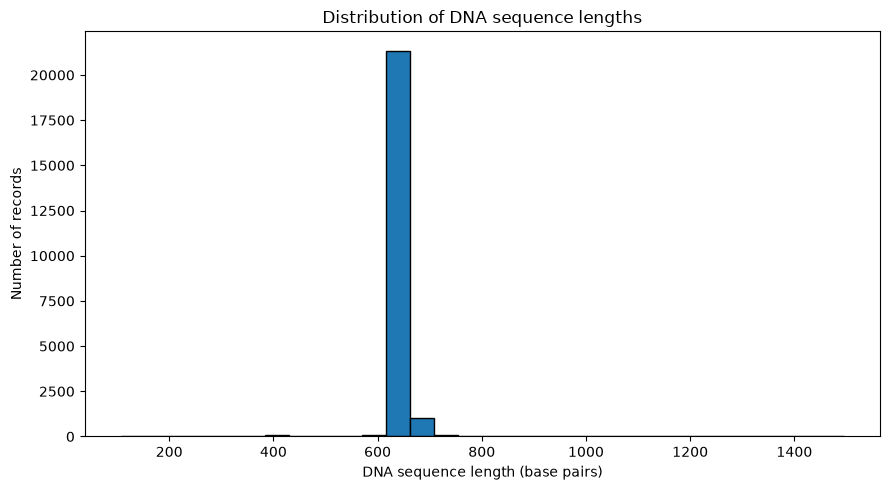

In [5]:
sequences = (
    df["nuc"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.replace(r"\s+", "", regex=True)
)

sequence_lengths = sequences.str.len()

print(sequence_lengths.describe())

plt.figure(figsize=(9, 5))
plt.hist(sequence_lengths, bins=30, edgecolor="black")
plt.xlabel("DNA sequence length (base pairs)")
plt.ylabel("Number of records")
plt.title("Distribution of DNA sequence lengths")
plt.tight_layout()
plt.show()


In [ ]:
# Work on a copy so the original dataset remains unchanged
data = df.copy()

# Normalize sequence text
data["clean_sequence"] = (
    data["nuc"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.replace(r"\s+", "", regex=True)
)

# Apply filtering conditions
filtered = data[
    (data["marker_code"] == "COI-5P")
    & (data["identification_rank"] == "species")
    & (data["species"].notna())
    & (data["species"].str.strip() != "")
    & (data["clean_sequence"].str.len() >= 500)
    & (data["clean_sequence"].str.fullmatch(r"[ACGT]+"))
].copy()

print("Original records:", len(df))
print("Records after filtering:", len(filtered))
print("Species remaining:", filtered["species"].nunique())
print("Distinct DNA sequences:", filtered["clean_sequence"].nunique())

filtered[["species", "marker_code", "clean_sequence"]].head()


Original records: 22818
Records after filtering: 19525
Species remaining: 463
Distinct DNA sequences: 5263


,species,marker_code,clean_sequence
0,Pyrgus warrenensis,COI-5P,AACTTTATATTTTATTTTCGGAATTTGAGCAGGAATAGTAGGTACT...
1,Erebia pluto,COI-5P,AACTTTATATTTTATTTTTGGAATTTGAGCAGGTATAATAGGAACC...
2,Erebia pluto,COI-5P,AACTTTATATTTTATTTTTGGAATTTGAGCAGGTATAATAGGAACC...
3,Minois dryas,COI-5P,AACATTATATTTTATTTTTGGAATTTGAGCAGGTATAGTAGGAACA...
4,Minois dryas,COI-5P,AACATTATATTTTATTTTTGGAATTTGAGCAGGTATAGTAGGAACA...


In [ ]:
# Count records belonging to each species
species_counts = (
    filtered["species"]
    .value_counts()
    .rename_axis("species")
    .reset_index(name="record_count")
)

print("Total eligible records:", len(filtered))
print("Total eligible species:", filtered["species"].nunique())

print("\nRecords per species:")
display(species_counts)

print("\nSpecies with fewer than 5 records:",
      (species_counts["record_count"] < 5).sum())

print("Species with fewer than 10 records:",
      (species_counts["record_count"] < 10).sum())

print("Species with at least 20 records:",
      (species_counts["record_count"] >= 20).sum())


Total eligible records: 19525
Total eligible species: 463

Records per species:


,species,record_count
0,Maniola jurtina,600
1,Polyommatus icarus,358
2,Leptidea sinapis,322
3,Lasiommata megera,300
4,Aricia agestis,286
...,...,...
458,Hipparchia christenseni,1
459,Polyommatus aroaniensis,1
460,Euphydryas italica,1
461,Zegris meridionalis,1



Species with fewer than 5 records: 60
Species with fewer than 10 records: 140
Species with at least 20 records: 239


In [ ]:
species_summary = (
    filtered.groupby("species")
    .agg(
        record_count=("clean_sequence", "size"),
        distinct_sequences=("clean_sequence", "nunique")
    )
    .sort_values("record_count", ascending=True)
)

print("Total species:", len(species_summary))

print("\nSpecies with fewer than 5 records:")
display(species_summary[species_summary["record_count"] < 5])

print("\nSpecies with only 1 distinct DNA sequence:")
display(species_summary[species_summary["distinct_sequences"] == 1])

print("\nSummary of records per species:")
display(species_summary["record_count"].describe())


Total species: 463

Species with fewer than 5 records:


,record_count,distinct_sequences
species,,
Zerynthia cerisy,1,1
Polyommatus aroaniensis,1,1
Lycaena dimorpha,1,1
Hipparchia christenseni,1,1
Euphydryas italica,1,1
Hipparchia autonoe,1,1
Zegris meridionalis,1,1
Tongeia fischeri,1,1
Erebia cyclopius,1,1



Species with only 1 distinct DNA sequence:


,record_count,distinct_sequences
species,,
Zerynthia cerisy,1,1
Polyommatus aroaniensis,1,1
Lycaena dimorpha,1,1
Hipparchia christenseni,1,1
Euphydryas italica,1,1
Hipparchia autonoe,1,1
Zegris meridionalis,1,1
Tongeia fischeri,1,1
Erebia cyclopius,1,1



Summary of records per species:


count    463.000000
mean      42.170626
std       58.275386
min        1.000000
25%        7.000000
50%       21.000000
75%       53.500000
max      600.000000
Name: record_count, dtype: float64

In [ ]:
# Count how many distinct sequences each species has
print("Species grouped by number of distinct DNA sequences:")

print(
    species_summary["distinct_sequences"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nSpecies with at least 5 distinct sequences:",
      (species_summary["distinct_sequences"] >= 5).sum())

print("Species with at least 10 distinct sequences:",
      (species_summary["distinct_sequences"] >= 10).sum())

print("Species with at least 20 distinct sequences:",
      (species_summary["distinct_sequences"] >= 20).sum())


Species grouped by number of distinct DNA sequences:
distinct_sequences
1      54
2      40
3      59
4      35
5      23
6      25
7      29
8      19
9      12
10     11
11     10
12     13
13      6
14      4
15      5
16     10
17      6
18      8
19      8
20     10
21      7
22      6
23      5
24      4
25      4
26      4
27      1
28      3
29      1
30      2
31      1
32      3
33      2
34      4
35      1
36      3
37      2
38      3
39      2
41      1
43      1
44      1
46      2
48      1
49      1
51      1
63      2
68      1
70      1
72      1
77      1
78      1
84      1
109     1
124     1

Species with at least 5 distinct sequences: 275
Species with at least 10 distinct sequences: 167
Species with at least 20 distinct sequences: 86


In [ ]:
# Find exact DNA sequences associated with multiple species

sequence_species = (
    filtered.groupby("clean_sequence")["species"]
    .nunique()
)

shared_sequences = sequence_species[sequence_species > 1]

print("Total distinct DNA sequences:",
      filtered["clean_sequence"].nunique())

print("Sequences associated with multiple species:",
      len(shared_sequences))

print("Records using these shared sequences:",
      filtered["clean_sequence"].isin(shared_sequences.index).sum())

# Inspect examples
if len(shared_sequences) > 0:
    shared_examples = filtered[
        filtered["clean_sequence"].isin(shared_sequences.index)
    ][["species", "clean_sequence"]].drop_duplicates()

    display(shared_examples.head(20))


Total distinct DNA sequences: 5263
Sequences associated with multiple species: 62
Records using these shared sequences: 1293


,species,clean_sequence
0,Pyrgus warrenensis,AACTTTATATTTTATTTTCGGAATTTGAGCAGGAATAGTAGGTACT...
33,Colias crocea,AACTTTATATTTTATTTTTGGAGTATGAGCAGGAATAATTGGAACT...
50,Iphiclides podalirius,AACATTATATTTCATTTTTGGAATTTGATCAGGAATAGTAGGAACT...
59,Maniola jurtina,AACTTTATATTTTATTTTTGGAATTTGAGCAGGAATAGTAGGAACT...
73,Hipparchia alcyone,AACTTTATATTTTATTTTTGGAATTTGAGCAGGAATGGTAGGAACA...
75,Melitaea phoebe,TACATTATATTTTATTTTTGGAATTTGAGCAGGTATATTAGGAACT...
94,Hipparchia semele,AACTTTATATTTTATTTTTGGTATTTGAGCAGGAATAGTAGGGACT...
108,Coenonympha arcania,AACATTATACTTTATTTTTGGAATTTGAGCAGGTATAATAGGAATA...
123,Callophrys rubi,AACTTTATATTTTATTTTTGGAATTTGAGCTGGAATATTAGGAACA...
141,Plebejus argyrognomon,AACATTATATTTTATTTTTGGAATTTGAGCAGGAATAGTAGGAACA...


In [ ]:
# Inspect every sequence associated with multiple species

shared_label_details = (
    filtered[
        filtered["clean_sequence"].isin(shared_sequences.index)
    ]
    .groupby("clean_sequence")
    .agg(
        species_count=("species", "nunique"),
        species_labels=("species", lambda x: sorted(set(x))),
        record_count=("species", "size")
    )
    .sort_values(
        ["species_count", "record_count"],
        ascending=False
    )
)

display(shared_label_details)


,species_count,species_labels,record_count
clean_sequence,,,
AACTTTATATTTTATTTTTGGAATTTGAGCAGGAATAGTAGGTACATCTCTTAGTCTTATTATTCGAACAGAATTAGGCACCCCAGGATCTTTAATTGGAAATGATCAAATTTATAATACTATTGTTACAGCTCATGCTTTTATTATAATTTTTTTTATAGTTATACCCATTATAATTGGAGGATTTGGTAATTGACTTATTCCCCTCATACTAGGAGCTCCTGACATAGCTTTCCCCCGAATAAATAATATAAGATTTTGACTTCTTCCACCTTCTTTAACCCTACTAATTTTAAGTAGTATTGTAGAAAATGGAGCTGGCACAGGATGAACGGTTTATCCCCCCCTTTCATCTAATATTGCCCATAGTGGATCCTCTGTTGATTTAGCAATTTTTTCTTTACATTTAGCTGGAATTTCATCTATTCTTGGAGCTATTAATTTTATTACAACAATTATTAATATACGAATTAATAATATAAATTATGATCAAATACCCCTATTTGTCTGAGCTGTAGGAATTACAGCATTATTATTATTACTTTCCCTACCGGTATTAGCCGGAGCTATTACAATACTTCTTACAGATCGAAATTTAAATACTTCTTTTTTTGATCCTGCAGGAGGAGGAGATCCTATTTTATATCAACATTTATTT,5,"[Erebia arvernensis, Erebia calcarius, Erebia ...",35
AACTTTATATTTTATTTTTGGAGTATGAGCAGGAATAATTGGAACTTCTTTAAGTTTAATAATTCGTACAGAATTAGGTAACCCTGGGTCACTAATTGGAGATGATCAAATTTATAATACTATTGTTACAGCTCATGCTTTTATTATAATTTTTTTTATAGTTATACCAATTATAATTGGAGGATTTGGTAATTGATTAATTCCCTTAATATTAGGAGCCCCTGATATAGCTTTCCCACGTATAAATAATATAAGATTTTGATTATTACCCCCATCATTAACTTTATTAATTTCTAGAAGTATTGTTGAAAATGGAGCAGGAACAGGATGAACAGTTTACCCCCCTCTTTCCTCTAATATTGCCCATAGAGGATCTTCTGTTGATTTAGCTATTTTTTCTCTACATCTTGCAGGAATTTCCTCCATCCTCGGAGCAATTAACTTTATTACAACAATTATCAATATACGAATTAATAATATATCATTTGATCAAATACCTTTATTTGTATGAGCAGTAGGAATTACTGCTTTATTATTATTATTATCATTACCGGTTTTAGCTGGTGCAATTACTATATTATTAACTGATCGAAATTTAAATACCTCTTTTTTTGACCCTGCTGGCGGAGGAGACCCAATTCTTTACCAACATTTATTT,3,"[Colias crocea, Colias croceus, Colias erate]",175
AACATTATATTTTATTTTTGGAATTTGAGCAGGAATAGTAGGAACATCTTTAAGAATCTTAATTCGTATAGAATTAGGAACTCCTGGATCTTTAATTGGAGATGATCAAATTTATAATACTATTGTTACAGCTCATGCATTTATTATAATTTTTTTTATAGTTATACCTATTATAATTGGAGGATTTGGTAATTGATTAGTACCTTTAATATTAGGGGCTCCAGATATAGCTTTCCCTCGAATAAATAATATAAGATTTTGATTATTACCCCCATCTTTAATATTATTAATTTCTAGAAGAATTGTAGAAAATGGGGCAGGAACAGGATGAACAGTTTACCCACCACTTTCATCTAATATTGCACATAGAGGATCATCTGTAGATTTAGCAATTTTCTCACTTCATTTAGCAGGAATTTCTTCAATTTTAGGAGCTATTAATTTTATTACAACTATTATTAATATACGAGTAAATAATTTATCTTTTGATCAAATATCATTATTTATTTGAGCAGTCGGAATTACTGCATTACTATTACTTTTATCTCTACCAGTATTAGCCGGAGCAATTACTATATTATTAACTGATCGAAATCTTAATACTTCATTTTTTGATCCAGCTGGAGGAGGAGATCCAATTTTATATCAACATTTATTC,3,"[Plebejus argyrognomon, Plebejus bellieri, Ple...",23
AACATTATATTTCATTTTTGGAATTTGATCAGGAATAGTAGGAACTTCATTAAGAATAATTATTCGAACTGAATTAGGTAATCCAGGTTCTTTAATTGGAGATGATCAAATTTATAATACTATTGTAACAGCACATGCTTTTATTATAATTTTTTTTATAGTTATACCAATTATAATTGGAGGATTTGGTAATTGATTAGTACCTTTAATATTAGGAGCTCCTGATATAGCATTTCCTCGTATAAATAATATAAGATTTTGATTATTACCCCCCTCTCTAATTCTATTAATTTCAAGAAGAATTGTAGAAAATGGTGCAGGAACTGGATGAACAGTCTACCCCCCACTATCATCTAATATTGCACATAGAGGAAGATCTGTTGATCTTGCTATTTTTTCACTTCACTTAGCTGGTATTTCATCTATTTTAGGTGCAATTAATTTTATTACAACAATTATTAATATACGAATTAATAATATATCATTTGATCAAATACCTTTATTTATTTGAGCTGTTGGAATTACAGCATTATTATTACTTTTATCTTTACCAGTATTAGCTGGAGCTATTACCATATTACTTACCGATCGAAATTTAAATACTTCATTTTTTGATCCAGCAGGAGGAGGAGATCCTATTTTATATCAACATTTATTT,2,"[Iphiclides feisthamelii, Iphiclides podalirius]",72
AACTTTATATTTTATCTTCGGAATTTGATCAGGGATAGTAGGAACATCTTTAAGTTTACTTATTCGAACTGAATTAGGAAATCCAGGATTTTTAATTGGTGACGACCAAATTTATAATACTATTGTAACAGCTCATGCTTTTATTATAATTTTTTTTATAGTTATACCCATTATAATTGGAGGATTTGGAAATTGATTAGTCCCATTAATACTAGGAGCTCCAGATATAGCTTTCCCCCGAATAAATAATATAAGATTTTGATTATTACCCCCTTCTTTAACTCTTCTTATTTCAAGCAGAATCGTAGAAAATGGAGCAGGAACAGGATGAACAGTGTACCCCCCACTATCATCAAATATTGCTCATAGAGGTTCATCAGTAGATTTAGCTATTTTTTCTTTACATTTAGCTGGAATTTCTTCAATTTTAGGAGCAATTAATTTTATTACAACTATTATTAATATACGTATTAGAAATATATCTTTTGATCAAATACCATTATTTGTATGATCAGTAGGAATTACTGCTTTACTTTTACTTCTTTCTTTACCGGTACTTGCAGGTGCTATTACAATACTTTTAACAGATCGAAATTTAAATACATCATTTTTTGATCCTGCTGGAGGAGGAGACCCAATTCTTTATCAACATCTATTT,2,"[Pieris bryoniae, Pieris napi]",69
...,...,...,...
AACTTTATATTTTATTTTTGGCGTATGAGCAGGAATAATTGGAACTTCTTTAAGTTTATTAATTCGTACAGAATTAGGTAATCCTGGATCACTAATTGGAGATGATCAAATTTATAATAGTATTGTTACAGCTCATGCCTTTATTATAATTTTTTTTATAGTTATGCCAATCATAATTGGAGGATTTGGTAATTGATTAATTCCTTTAATATTAGGAGCTCCTGATATAGCTTTCCCACGTATAAATAATATAAGATTTTGATTACTACCCCCATCATTAACTTTATTAATTTCTAGAAGTATTGTTGAAAACGGAGCAGGAACAGGATGAACAGTTTACCCCCCTCTTTCCTCTAATATTGCCCA

In [ ]:
# Count how often each species appears in a shared sequence

shared_species_counts = (
    filtered[
        filtered["clean_sequence"].isin(shared_sequences.index)
    ]
    .groupby("species")["clean_sequence"]
    .nunique()
    .sort_values(ascending=False)
)

print("Species involved in shared-sequence cases:")
display(shared_species_counts.head(30))

print(
    "\nNumber of species involved:",
    len(shared_species_counts)
)


Species involved in shared-sequence cases:


species
Erebia euryale             5
Erebia ligea               5
Pyrgus alveus              4
Hipparchia semele          4
Coenonympha arcania        3
Coenonympha gardetta       3
Erebia cassioides          3
Pyrgus warrenensis         3
Colias myrmidone           2
Erebia albergana           2
Colias caucasica           2
Colias crocea              2
Plebejus idas              2
Pseudophilotes baton       2
Plebejus argyrognomon      2
Pieris bryoniae            2
Melitaea celadussa         2
Melitaea athalia           2
Oeneis glacialis           2
Oeneis norna               2
Erebia alberganus          2
Erebia arvernensis         2
Iphiclides feisthamelii    2
Hipparchia volgensis       2
Hipparchia syriaca         2
Hipparchia fagi            2
Cupido minimus             2
Colias erate               2
Maniola jurtina            2
Maniola telmessia          2
Name: clean_sequence, dtype: int64


Number of species involved: 76
